# P02 — 4번 헤드 POL(P7) IN·OUT 호스 터짐 → 호스 교체 (2026-10-20 00:10)

정리본: [`cases/P02.md`](cases/P02.md). 이 노트북은 그 근거를 다시 만든다.
원시 데이터는 `cache/raw/pump/` 일별 CSV(`extract_raw_csv.py`)를 쓰고, CSV에 없는 태그(재생용 사출 신호·알람 비트·가동 플래그, HD4 트립·인버터 FWD·압력 스위치·인젝션 SOL)만 DB에서 하루씩 받아 캐시한다.
공용 함수는 [`hd4_common.py`](hd4_common.py) (P03·P04와 같이 씀).

| 단계 | 내용 |
|---|---|
| 1 | 일지 |
| 2 | 그때 경고 이력 (P7·I7) |
| 3 | 작업 구간 원시 신호 — 정지·시운전·재가동 |
| 4 | 언제 터졌나 — 정지 시각, 정지 직전 압력 |
| 5 | 고정 조건으로 본 저항 — 교체가 저항을 바꿨나 |
| 6 | 재생 — 일별 피처 추세 |
| 7 | 그때 모델 상태 |

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from review_lib import paths, plot          # plot: 한글 글꼴 설정
import hd4_common as h
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)
FIGS = paths.CHECK_DIRS["pump"] / "figs"; FIGS.mkdir(exist_ok=True)
INC = pd.read_csv("labels_incidents.csv")
INC = INC[INC.incident_id.isin(["P02", "P03", "P04"])]
EV = h.EVENTS["P02 호스 교체"]

## 1. 일지

공무반·기계실 두 기록이 같은 사건이다(중복의심=예). 기계실 원문 '24:40'은 10-20 00:40이다.

In [2]:
h.actions("P02")[["작업ID", "journal", "start_dt", "end_dt", "설비상세", "조치", "담당", "확인메모"]]

,작업ID,journal,start_dt,end_dt,설비상세,조치,담당,확인메모
2,G-01-010,공무반,2026-10-20 00:10:00,2026-10-20 01:00:00,"4번 헤드 POL IN, OUT 호스 터짐",호스 교체,"장철용,황성빈",잔업; 기계실 업무일지에도 유사 작업 기재; 완전 동일 이벤트인지 확인 필요
3,M-01-02-3-2,기계실,2026-10-20 00:40:00,2026-10-20 01:20:00,"발포2라인 4번헤드 POLYOL IN,OUT 호스 누수로 교체",호스 교체,"공무,기계",원문 NO.3 하단 별도 작업문장; 24:40 원문 시각 유지; 공무반에도 유사한 작업 기록 존재; 동일 사건일 가능성 확인 필요


## 2. 그때 경고 이력 (P7·I7)

같은 설비키(PUMP_P7·HEAD_HD4)로 조치 전 7일 안에 떠 있던 경고가 짝 후보다.

In [3]:
ep = h.episodes()
ep[(ep.onset < "2026-10-21") & (ep.last_detected > "2026-10-12")][["episode_id", "key", "onset", "last_detected", "cleared", "reasons", "message_first", "top_features"]]

,episode_id,key,onset,last_detected,cleared,reasons,message_first,top_features
2,W0003,I7,2026-10-15 18:59:26.015,2026-10-25 08:50:00.624,NaT,pump_line_resistance_low;pump_head_resistance_high;pump_line_resistance_high,토출 배관 저항 감소 · 같은 유량 대비 압력 하강 (노즐 열림·누설 의심),r_phys;P0;decel_half_sec;release_half_sec;t_self
5,W0006,P7,2026-10-15 22:29:03.012,2026-10-16 07:30:25.056,2026-10-16 10:50:00.312,pump_response_change;pump_line_resistance_high,펌프 응답 변화 · 증압·감속·압력해제 시간이 평소와 다름 (모터·인버터·밸브 점검),P0;r_phys;pt_std;t_self;pump_resid
11,W0012,P7,2026-10-17 06:57:02.215,2026-10-24 22:37:51.791,2026-10-25 08:50:00.623,pump_line_resistance_high;pump_head_resistance_high,토출 배관·노즐 저항 증가 · 같은 유량 대비 압력 상승,r_phys;pt_std;P0;t_self;decel_half_sec


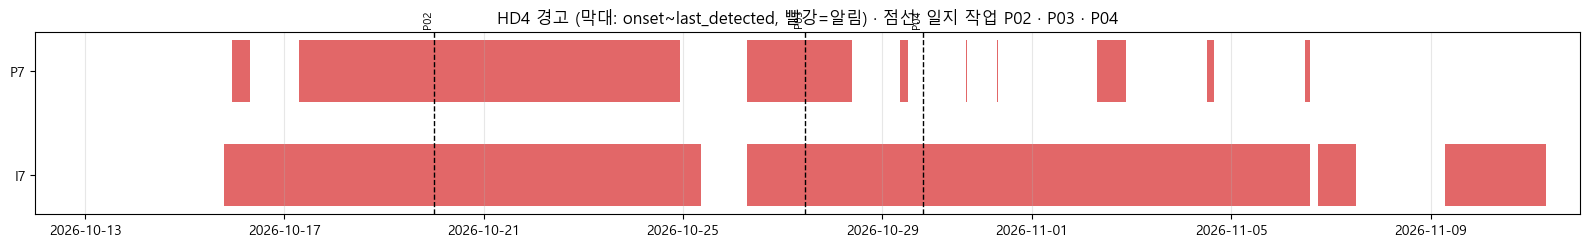

In [4]:
fig, ax = plt.subplots(figsize=(16, 2.6))
plot.timeline(h.episodes(), INC, start=pd.Timestamp("2026-10-12"), end=pd.Timestamp("2026-11-12"), ax=ax)
ax.set_title("HD4 경고 (막대: onset~last_detected, 빨강=알림) · 점선: 일지 작업 P02 · P03 · P04")
fig.tight_layout(); fig.savefig(FIGS / "HD4_timeline.png", dpi=110, bbox_inches="tight")

## 3. 작업 구간 원시 신호

- `Pump_Run_P7` · `FWD_P7`(`P00209`, 인버터 FWD = 가동 지령) · `INJ_SOL_HD4`(`P00280`, 헤드 인젝션 SOL) · `PSW_P7`(`P00062`, 압력 스위치)
- PT 65535 근처(0 밑을 부호 없는 16비트로 읽은 값)는 비웠다.

In [5]:
# 원시 데이터 — cache/raw/pump 일별 CSV + HD4 릴레이(DB, 하루 캐시). 10-06 ~ 11-12 전체 약 30초
R = h.raw()
R[["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Hz_I7", "BU_I7", "Pump_Run_P7", "FWD_P7", "INJ_SOL_HD4"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
FT_P7,6339884.0,1426.8,1155.5,0.0,0.0,1811.0,2614.0,9978.0
PT_P7,6210010.0,76.5,57.5,0.0,3.0,97.0,128.0,187.0
Hz_P7,6339884.0,2890.4,631.1,2500.0,2500.0,2500.0,3622.0,4320.0
BU_P7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
FT_I7,6339884.0,647.8,545.7,0.0,0.0,771.0,1119.0,9554.0
PT_I7,6327369.0,35.6,34.7,0.0,3.0,28.0,58.0,141.0
Hz_I7,6339884.0,3663.0,1105.1,3000.0,3000.0,3000.0,4081.0,6354.0
BU_I7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
Pump_Run_P7,6339884.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0
FWD_P7,6339598.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0


In [6]:
w = R.loc["2026-10-19 23:30":"2026-10-20 07:00"]
cols = ["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Pump_Run_P7", "FWD_P7", "Trip_P7", "PSW_P7", "INJ_SOL_HD4"]
w[cols].resample("5min").max().loc[lambda x: (x.index < "2026-10-20 01:30") | (x.index > "2026-10-20 05:55")]

,FT_P7,PT_P7,Hz_P7,BU_P7,FT_I7,PT_I7,Pump_Run_P7,FWD_P7,Trip_P7,PSW_P7,INJ_SOL_HD4
Time,,,,,,,,,,,
2026-10-19 23:30:00,3111,166.0,4320,1,1641,103.0,1,1.0,0.0,1.0,1.0
2026-10-19 23:35:00,3140,166.0,4320,1,1616,105.0,1,1.0,0.0,1.0,1.0
2026-10-19 23:40:00,3096,165.0,4320,1,1517,98.0,1,1.0,0.0,1.0,1.0
2026-10-19 23:45:00,3126,169.0,4320,1,1591,105.0,1,1.0,0.0,1.0,1.0
2026-10-19 23:50:00,3096,166.0,4320,1,1517,98.0,1,1.0,0.0,1.0,1.0
2026-10-19 23:55:00,3169,164.0,4320,1,1604,104.0,1,1.0,0.0,1.0,1.0
2026-10-20 00:00:00,1840,103.0,2500,0,796,33.0,1,1.0,0.0,1.0,0.0
2026-10-20 00:05:00,0,7.0,2500,0,0,7.0,0,0.0,0.0,1.0,0.0
2026-10-20 00:10:00,0,7.0,2500,0,0,7.0,0,0.0,0.0,1.0,0.0


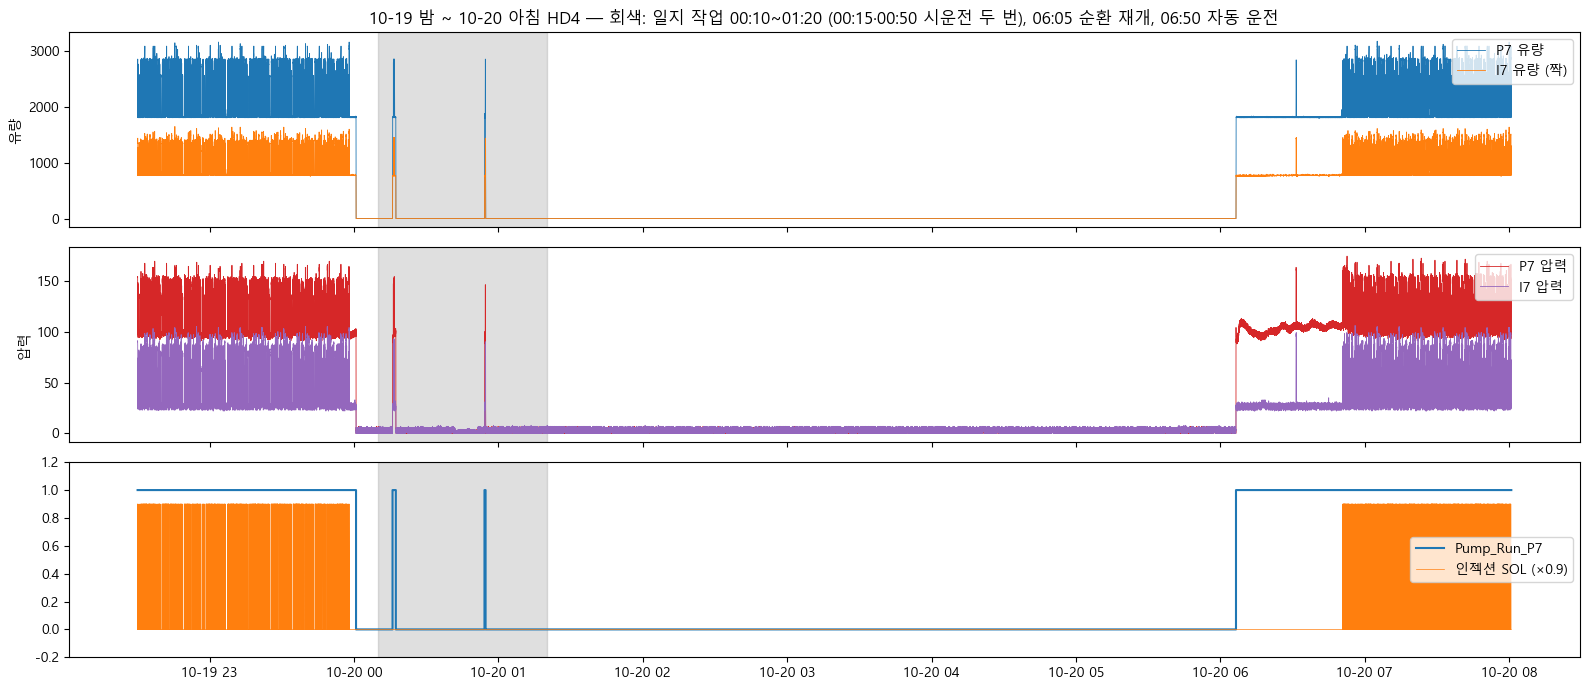

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True)
seg = R.loc["2026-10-19 22:30":"2026-10-20 08:00"]
axes[0].plot(seg.index, seg.FT_P7, lw=0.6, label="P7 유량"); axes[0].plot(seg.index, seg.FT_I7, lw=0.6, label="I7 유량 (짝)")
axes[0].set_ylabel("유량"); axes[0].legend(loc="upper right")
axes[1].plot(seg.index, seg.PT_P7, lw=0.6, color="tab:red", label="P7 압력"); axes[1].plot(seg.index, seg.PT_I7, lw=0.6, color="tab:purple", label="I7 압력")
axes[1].set_ylabel("압력"); axes[1].legend(loc="upper right")
axes[2].step(seg.index, seg.Pump_Run_P7, where="post", label="Pump_Run_P7")
axes[2].step(seg.index, seg.INJ_SOL_HD4 * 0.9, where="post", lw=0.5, label="인젝션 SOL (×0.9)"); axes[2].legend(loc="center right"); axes[2].set_ylim(-0.2, 1.2)
for ax in axes:
    ax.axvspan(*EV, color="gray", alpha=0.25)
axes[0].set_title("10-19 밤 ~ 10-20 아침 HD4 — 회색: 일지 작업 00:10~01:20 (00:15·00:50 시운전 두 번), 06:05 순환 재개, 06:50 자동 운전")
fig.tight_layout(); fig.savefig(FIGS / "P02_window.png", dpi=110, bbox_inches="tight")

## 4. 언제 터졌나

호스가 운전 중에 터졌다면 정지 시각이 평소와 다르거나, 정지 직전에 압력이 빠졌을 것이다.
- 매일 밤 `Pump_Run_P7`이 꺼진 시각 (평소 23:58~00:01)
- 10-19 마지막 자동 운전 1시간의 P7 압력을 같은 Hz의 다른 날 밤과 비교

In [8]:
pr = R.Pump_Run_P7
off = pr[(pr.shift() == 1) & (pr == 0)].index
off = pd.Series(off[(off.hour >= 22) | (off.hour < 2)])
t = off.groupby((off - pd.Timedelta(hours=6)).dt.date).agg(["first", "last", "size"]); t.index = pd.to_datetime(t.index)
t.loc["2026-10-12":"2026-10-24"]          # size > 1 = 정지 뒤 다시 돌린 적 있음 (10-19: 00:00 정지 → 00:15·00:50 시운전)

,first,last,size
Time,,,
2026-10-12,2026-10-12 23:58:45.483796,2026-10-12 23:58:45.483796,1
2026-10-13,2026-10-13 23:55:00.729629,2026-10-14 00:18:13.086145,3
2026-10-14,2026-10-14 23:59:11.475297,2026-10-14 23:59:11.475297,1
2026-10-15,2026-10-15 23:59:46.159012,2026-10-15 23:59:46.159012,1
2026-10-16,2026-10-16 23:59:00.991137,2026-10-16 23:59:00.991137,1
2026-10-17,2026-10-18 00:03:38.892116,2026-10-18 00:03:38.892116,1
2026-10-19,2026-10-20 00:00:48.167539,2026-10-20 00:54:39.184235,3
2026-10-20,2026-10-21 00:00:27.444722,2026-10-21 00:00:27.444722,1
2026-10-21,2026-10-21 23:59:03.050714,2026-10-21 23:59:03.050714,1


In [9]:
# 정지 직전 1시간 (23:00~24:00) 자동 운전 — 같은 Hz 단계끼리 날짜별 K
s = h.steady(R, "P7", 1)
late = s[(s.index.hour == 23)]
t = late.groupby(["day", "Hz"]).K.median().unstack(); t.index = pd.to_datetime(t.index)
t.loc["2026-10-12":"2026-10-24"].dropna(axis=1, thresh=5).round(2)

Hz,3650,3929
day,,
2026-10-12,19.36,17.53
2026-10-13,19.53,17.74
2026-10-14,19.74,17.62
2026-10-15,19.53,NaN
2026-10-16,20.78,NaN
2026-10-17,20.78,19.17
2026-10-20,20.03,17.94
2026-10-21,20.17,17.47
2026-10-22,19.73,17.28


## 5. 고정 조건으로 본 저항 — 교체가 저항을 바꿨나

호스가 새면 같은 유량에서 압력이 덜 걸린다(K ↓). 교체 전후 K가 그대로면 데이터에는 누수가 안 보였다는 뜻이다.

In [10]:
# 같은 Hz 단계끼리 이어 본 증압(자동 운전) 저항 K = PT/(FT/1000)² — 레시피가 바뀌어도 비교가 된다
kp, ki = h.hz_table(R, "P7"), h.hz_table(R, "I7")
pd.concat({"P7": kp, "I7": ki}, axis=1).loc["2026-10-06":"2026-10-27"].round(2)

P7                          I7                     
Hz           3650   3901   3929   3971   5057   5631   5711   6032
day                                                               
2026-10-06  19.16    NaN  16.86    NaN  40.89    NaN  41.84    NaN
2026-10-07  19.10    NaN  16.77  18.18  48.90    NaN  48.74    NaN
2026-10-08  19.03    NaN  16.71    NaN  45.17    NaN  45.48    NaN
2026-10-09  18.96    NaN  16.52  18.54  42.11    NaN  41.84    NaN
2026-10-10  19.39    NaN  17.63  17.48  43.07    NaN  42.32    NaN
2026-10-12  19.17    NaN  17.43  17.45  42.72    NaN  44.50    NaN
2026-10-13  19.27    NaN  17.56    NaN  39.55    NaN  39.44    NaN
2026-10-14  19.68  17.99  17.68  18.18  42.29    NaN  41.84  36.33
2026-10-15  19.53  17.87  17.68    NaN  43.33    NaN  42.80  42.88
2026-10-16  20.55  18.66  18.30  18.99  43.33    NaN  42.74  43.02
2026-10-17  20.83    NaN  19.17    NaN  43.33    NaN  42.80    NaN
2026-10-19  19.82    NaN    NaN  18.99  43.33    NaN    NaN    NaN
2026-10-20  19.97  18.70  17.62    NaN  43.30    NaN  42.80  43.02
2026-10-21  19.88    NaN  17.43    NaN  43.33    NaN  42.80    NaN
2026-10-22  20.03    NaN  17.56  17.51  43.33  42.83  42.80    NaN
2026-10-23  19.93  18.37  17.57  18.21  52.24  51.67  51.80  51.66
2026-10-24  19.97    NaN  17.56  17.57  52.24  51.61  51.35    NaN
2026-10-26  20.11    NaN  17.54  17.43  52.24  51.61  51.35    NaN
2026-10-27  19.96    NaN  17.62  17.54  52.11  51.61  51.35    NaN

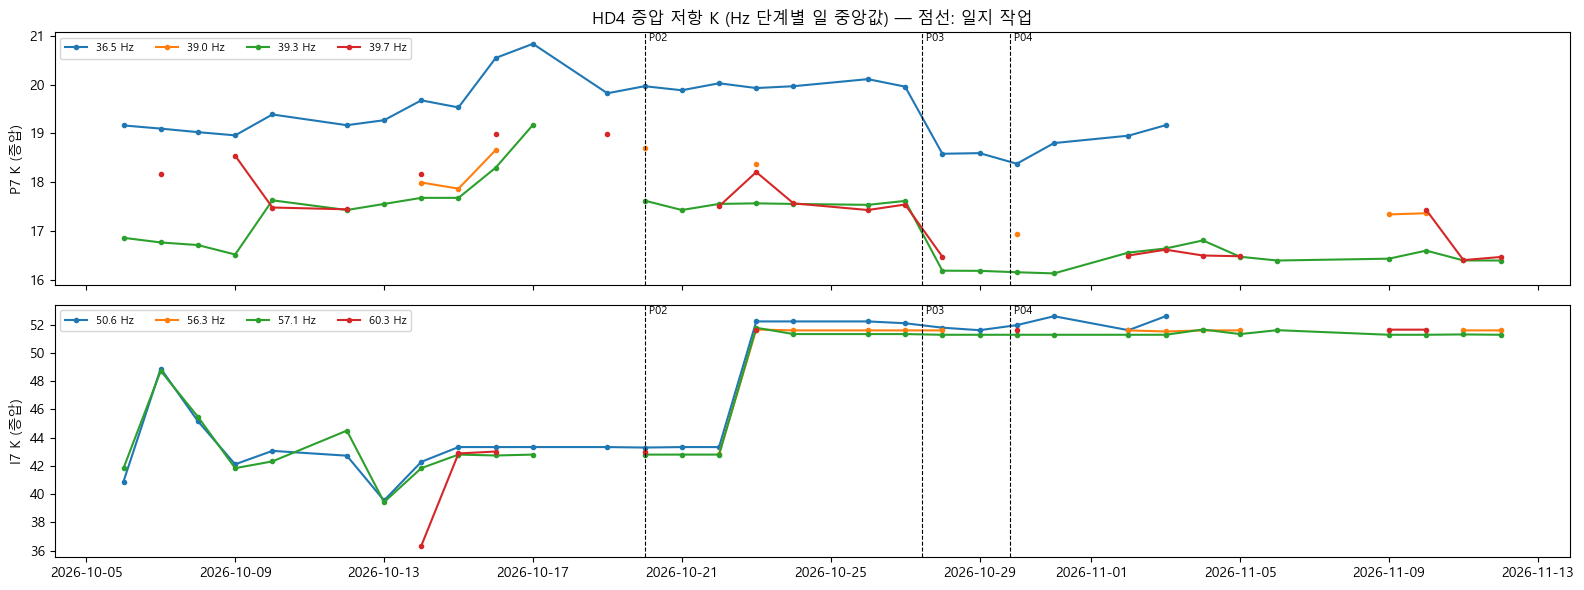

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for ax, (p, t) in zip(axes, [("P7", kp), ("I7", ki)]):
    for hz in t.columns:
        ax.plot(t.index, t[hz], "o-", ms=3, label=f"{hz / 100:.1f} Hz")
    ax.set_ylabel(f"{p} K (증압)"); ax.legend(loc="upper left", ncol=4, fontsize=8)
    h.mark(ax, label=True)
axes[0].set_title("HD4 증압 저항 K (Hz 단계별 일 중앙값) — 점선: 일지 작업")
fig.tight_layout(); fig.savefig(FIGS / "P02_K.png", dpi=110, bbox_inches="tight")

In [12]:
# 작업 직전(10-19 밤 4시간) vs 재가동 뒤(10-20 06:00부터 4시간) — 같은 Hz 단계
RESTART = pd.Timestamp("2026-10-20 06:00")
pd.concat({"P7 증압": h.before_after(R, "P7", EV[0], RESTART), "P7 순환": h.before_after(R, "P7", EV[0], RESTART, buildup=0),
           "I7 증압": h.before_after(R, "I7", EV[0], RESTART), "I7 순환": h.before_after(R, "I7", EV[0], RESTART, buildup=0)}).round(2)

n              FT            PT             K             
구간               전       후       전       후     전      후      전      후   변화%
      Hz                                                                   
P7 순환 2500  4982.0  9005.0  1813.0  1812.0  98.0  102.0  29.69  30.80  3.72
I7 순환 3000  4981.0  9005.0   771.0   771.0  26.0   26.0  43.74  43.74  0.00

## 6. 재생 — 일별 피처 추세 (자동 운전 사이클 중앙값)

In [13]:
# 운영 펌프 모델 재생 (P7·I7, 10-06 ~ 11-12). 처음 한 번 약 1시간 반 → cache/replay/hd4_P7I7_1006_1112.pkl
C = h.replay_cycles()
dP7, dI7 = h.daily_features(C, "P7"), h.daily_features(C, "I7")
pd.concat({"P7": dP7, "I7": dI7}, axis=1).loc["2026-10-12":"2026-10-27"].round(3)

P7                                                                      ...     I7                                                                   
               n  알림창비율     PT     P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid  ...  알림창비율    PT    P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid   score
day                                                                                   ...                                                                          
2026-10-12  3209  0.001  143.0   96.0  1.005     -0.016  1.022  0.191  0.111  -0.001  ...  0.649  84.0  26.0  1.009      0.207  0.953 -0.979 -0.450  -0.019   2.916
2026-10-13  3426  0.003  143.5   96.0  1.005     -0.019  1.024  0.207  0.111  -0.003  ...  0.978  78.0  24.0  1.016      0.024  0.884 -2.414 -0.899  -0.047  16.181
2026-10-14  3509  0.003  145.0   97.0  1.005     -0.238  1.033  0.304  0.222  -0.077  ...  0.974  82.0  25.0  1.013     -0.043  0.937 -1.328 -0.674  -0.054   8.795
2026-10-15  3375  0.015  144.0   98.0  1.005     -0.220  1.034  0.303  0.333  -0.067  ...  0.977  85.0  26.0  1.009      0.062  0.948 -1.129 -0.450  -0.039   3.501
2026-10-16  3206  0.702  149.0  101.0  1.001     -0.541  1.095  0.902  0.667  -0.243  ...  0.978  84.0  26.0  1.009      0.022  0.946 -1.157 -0.450  -0.042   3.639
2026-10-17  2954  0.977  156.0  102.0  0.999     -0.544  1.110  1.189  0.778  -0.290  ...  0.966  84.0  26.0  1.009      0.002  0.946 -1.151 -0.450  -0.041   3.187
2026-10-19  3207  0.087  147.5   97.0  1.004     -0.369  1.054  0.484  0.222  -0.102  ...  0.977  84.0  26.0  1.009      0.083  0.947 -1.130 -0.450  -0.036   3.457
2026-10-20  3085  0.364  150.0   98.0  1.001     -0.535  1.071  0.666  0.333  -0.170  ...  0.976  84.5  26.0  1.009      0.051  0.946 -1.142 -0.450  -0.044   3.551
2026-10-21  3020  0.468  148.0   98.0  1.005     -0.019  1.064  0.621  0.333  -0.002  ...  0.974  84.5  26.0  1.013      0.546  0.951 -1.041 -0.450   0.028   3.029
2026-10-22  2790  0.527  149.0   98.0  1.001     -0.534  1.067  0.579  0.333  -0.169  ...  0.970  84.0  26.0  1.009      0.066  0.946 -1.168 -0.450  -0.043   4.091
2026-10-23  3010  0.332  149.0   97.0  1.002     -0.487  1.067  0.538  0.222  -0.132  ...  0.977  99.5  31.0  0.998      0.561  1.110  2.311  0.674   0.035   0.992
2026-10-24  3075  0.261  150.5   98.0  1.003     -0.280  1.067  0.597  0.333  -0.081  ...  0.979  99.0  31.0  1.000      0.658  1.112  2.328  0.674   0.046   0.879
2026-10-26  3251  0.448  149.0   98.0  1.001     -0.534  1.067  0.544  0.333  -0.161  ...  0.978  99.0  31.0  0.998      0.550  1.109  2.280  0.674   0.037   0.972
2026-10-27  3226  0.233  149.0   98.0  1.002     -0.534  1.064  0.624  0.333  -0.169  ...  0.978  99.0  31.0  0.998      0.545  1.107  2.228  0.674   0.027   0.896

[14 rows x 22 columns]

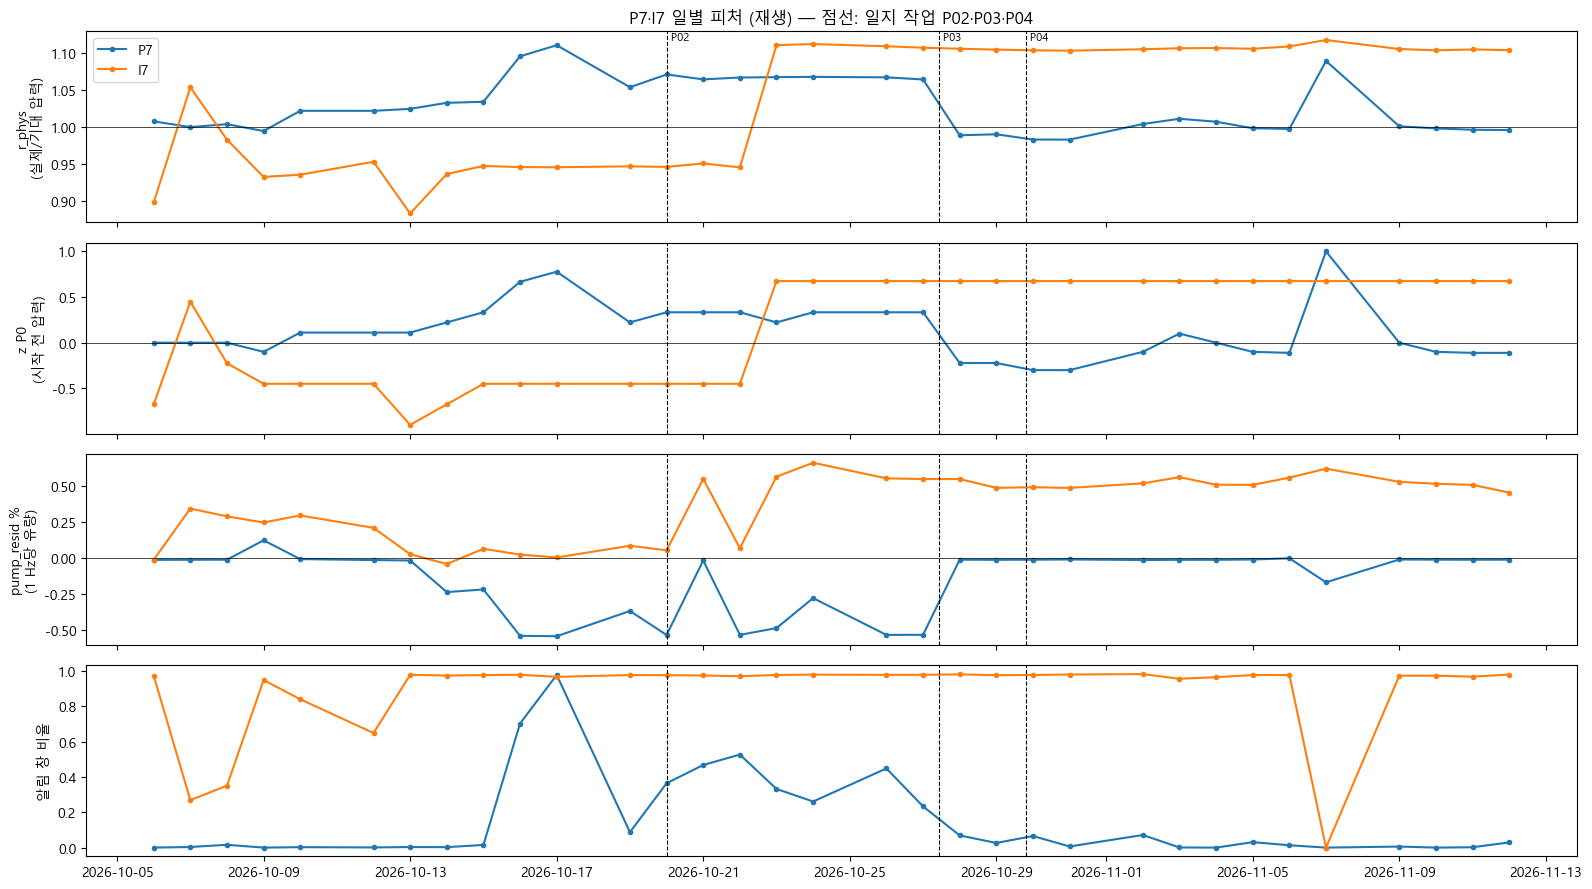

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=True)
for p, d, c in [("P7", dP7, "tab:blue"), ("I7", dI7, "tab:orange")]:
    axes[0].plot(d.index, d.r_phys, "o-", ms=3, color=c, label=p)
    axes[1].plot(d.index, d.z_P0, "o-", ms=3, color=c, label=p)
    axes[2].plot(d.index, d.pump_resid, "o-", ms=3, color=c, label=p)
    axes[3].plot(d.index, d["알림창비율"], "o-", ms=3, color=c, label=p)
axes[0].axhline(1, color="k", lw=0.5); axes[0].set_ylabel("r_phys\n(실제/기대 압력)")
axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("z P0\n(시작 전 압력)")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_ylabel("pump_resid %\n(1 Hz당 유량)")
axes[3].set_ylabel("알림 창 비율"); axes[0].legend(loc="upper left")
for ax in axes:
    h.mark(ax, label=ax is axes[0])
axes[0].set_title("P7·I7 일별 피처 (재생) — 점선: 일지 작업 P02·P03·P04")
fig.tight_layout(); fig.savefig(FIGS / "P02_trend.png", dpi=110, bbox_inches="tight")

## 7. 그때 모델 상태

- 00:00 정상 정지 → 화면 "정지". 사이클이 없으니 판정도 없다.
- 시운전 두 번(00:15·00:50)은 증압 비트가 켜졌다. 판정에 들어갔는지 본다.
- 06:50 첫 자동 사이클은 30분 넘게 멈췄다가 재가동한 것이라 창이 비워진 상태로 시작한다.

In [15]:
x = C[(C.pump.isin(["P7", "I7"])) & C.t.between("2026-10-19 23:00", "2026-10-20 08:00")]
x.groupby(["pump", x.t.dt.floor("30min"), "mode"]).agg(n=("t", "size"), score=("score", "median"), level=("pump_level", lambda s: s.value_counts().index[0] if s.notna().any() else None)).unstack("pump").head(30)

n           score           level     
pump                        I7   P7         I7        P7    I7   P7
t                   mode                                           
2026-10-19 23:00:00 자동 운전  113  113   3.353239  0.322457    알림   정상
2026-10-19 23:30:00 자동 운전   98   98   3.807322  0.239713    알림   정상
                    점검·수동    1    1   2.800609  0.265162   NaN  NaN
2026-10-20 00:00:00 점검·수동    2    2  17.075985  0.098606   NaN  NaN
2026-10-20 00:30:00 점검·수동    1    1  10.529039  0.311246   NaN  NaN
2026-10-20 06:30:00 자동 운전   33   33   3.151852  0.668602    정상   정상
                    점검·수동    1    1   0.134874  0.454788   NaN  NaN
2026-10-20 07:00:00 자동 운전  114  114   3.359884  0.435319    알림   알림
2026-10-20 07:30:00 자동 운전  110  110   3.481376  0.429583    알림   주의